<a href="https://colab.research.google.com/github/ercanaksakal/turkce-mini-gpt/blob/main/adim3_bpe_tokenizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adım 3 — Kendi BPE Tokenizer'ım ve Erken Durdurma
2. adımda model metni **karakter karakter** okuyordu. Gerçek dil modelleri (GPT, Claude, Llama) ise metni **kelime parçalarına** (token) böler. Bu defterde:

1. Metni normalleştireceğiz (tırnak ve tire çeşitlerini birleştirme)
2. **BPE (Byte Pair Encoding)** tokenizer'ını sıfırdan yazıp Türkçe Vikipedi ile eğiteceğiz
3. Aynı Mini GPT'yi bu tokenlarla eğiteceğiz
4. **Erken durdurma** ile en iyi modeli koruyacağız
5. Karakter modeliyle **adil** bir karşılaştırma yapacağız

**Adil karşılaştırma için:** Aynı veri (5 M karakter), aynı model boyutu, aynı dropout. Değişen tek şey tokenizer.

**Başlamadan önce:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU`.

## 1. Kurulum

In [ ]:
%pip install -q datasets

In [1]:
import os, re, math, time, json, unicodedata
from dataclasses import dataclass, asdict
from collections import Counter, defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337)
print("Cihaz:", device, "| PyTorch:", torch.__version__)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = "/content/drive/MyDrive/yapay_zeka_projesi"
except ImportError:
    PROJE = "./yapay_zeka_projesi"

VERI_DOSYASI = f"{PROJE}/veri/tr_vikipedi.txt"                  # 2. adımdaki veri
TOKENIZER_DOSYASI = f"{PROJE}/tokenizer/bpe_tr_2048.json"
CKPT_EN_IYI = f"{PROJE}/checkpoints/mini_gpt_bpe_en_iyi.pt"
for yol in [VERI_DOSYASI, TOKENIZER_DOSYASI, CKPT_EN_IYI]:
    os.makedirs(os.path.dirname(yol), exist_ok=True)
print("Proje klasörü:", PROJE)

Cihaz: cuda | PyTorch: 2.11.0+cu130
Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/yapay_zeka_projesi


## 2. Veri
2. adımda Drive'a kaydettiğimiz Vikipedi metnini okuyoruz. Dosya yoksa yeniden indirilir.

In [2]:
HEDEF_KARAKTER = 5_000_000

if os.path.exists(VERI_DOSYASI):
    with open(VERI_DOSYASI, encoding="utf-8") as f:
        ham_metin = f.read()
    print("Veri Drive'dan okundu.")
else:
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", "20231101.tr", split="train", streaming=True)
    parcalar, toplam = [], 0
    for makale in ds:
        parcalar.append(makale["text"]); toplam += len(makale["text"])
        if toplam >= HEDEF_KARAKTER:
            break
    ham_metin = "\n\n".join(parcalar)
    with open(VERI_DOSYASI, "w", encoding="utf-8") as f:
        f.write(ham_metin)
    print(f"{len(parcalar)} makale indirildi.")
print(f"Ham karakter sayısı: {len(ham_metin):,}")

Veri Drive'dan okundu.
Ham karakter sayısı: 5,009,681


## 3. Normalleştirme
2. adımda sözlükte `"`, `“`, `”` gibi aynı işi gören beş farklı tırnak vardı. Model bunları ayrı ayrı öğrenmek zorunda kalıyordu.
Şimdi bunları tek biçime indiriyoruz. Ayrıca **NFC** normalleştirmesi, görünüşte aynı ama farklı kodlanmış harfleri (ör. `ş` tek karakter / `s` + çengel) birleştirir.

In [3]:
DONUSUM = str.maketrans({"“": '"', "”": '"', "„": '"', "«": '"', "»": '"',
                         "‘": "'", "’": "'", "–": "-", "—": "-"})

def normallestir(s):
    return unicodedata.normalize("NFC", s).translate(DONUSUM)

metin = normallestir(ham_metin)
sayac = Counter(metin)
izinli = set(c for c, n in sayac.items() if n >= 50)
metin = "".join(c for c in metin if c in izinli)

temel_karakterler = sorted(izinli)
print("Temel karakter sayısı:", len(temel_karakterler), "(2. adımda 120 idi)")
print("".join(temel_karakterler))

Temel karakter sayısı: 114 (2. adımda 120 idi)

 !"$%&'()*+,-./0123456789:;<=>?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz| °²ÇÖÜáâäçèéêíîóöûüāćğİıŞş→


## 4. BPE nasıl çalışır?
Fikir çok basit:
1. Her kelimeyi karakterlerine ayır.
2. Tüm metinde **en sık yan yana gelen iki parçayı** bul (ör. `l` + `a`).
3. Onları tek bir yeni token yap (`la`) ve sözlüğe ekle.
4. Hedef sözlük boyutuna ulaşana kadar tekrarla.

Sonuçta sık kelimeler (`ve`, `bir`) ve ekler (`lar`, `ının`, `dir`) tek token olur; nadir kelimeler ise parçalara bölünür.
Türkçe gibi eklemeli bir dilde bu yöntem çok iyi çalışır: model `ev-ler-imiz-den` gibi parçaları ayrı ayrı öğrenebilir.

### Ön bölme
Önce metni kelime benzeri parçalara ayırıyoruz; BPE bu parçaların **sınırlarını aşmaz**. Kelimenin önündeki boşluk kelimeye dahil edilir (`" ev"`), böylece model kelime başlarını tanır. Rakamlar en fazla 3'lü gruplanır.

In [4]:
ON_AYIRICI = re.compile(r" ?[^\W\d_]+| ?\d{1,3}| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

ornek = "Türkiye'de 1923 yılında, 85 milyon kişi yaşıyor."
print(ON_AYIRICI.findall(ornek))

# Güvenlik kontrolü: parçalar birleşince metin birebir geri gelmeli (hiçbir karakter kaybolmamalı)
kontrol = metin[:200_000]
assert "".join(ON_AYIRICI.findall(kontrol)) == kontrol, "Ön bölme karakter kaybediyor!"
print("Ön bölme kontrolü geçti: karakter kaybı yok.")

['Türkiye', "'", 'de', ' 192', '3', ' yılında', ',', ' 85', ' milyon', ' kişi', ' yaşıyor', '.']
Ön bölme kontrolü geçti: karakter kaybı yok.


In [6]:
def bpe_egit(metin, hedef_sozluk, temel):
    """Metinden BPE birleştirme kurallarını öğrenir.
    Verimlilik için her adımda tüm metni yeniden saymak yerine,
    sadece birleşmeden etkilenen kelimelerin çift sayılarını günceller."""
    parca_sayilari = Counter(ON_AYIRICI.findall(metin))
    stoi = {c: i for i, c in enumerate(temel)}
    sozluk = {i: c for i, c in enumerate(temel)}            # id -> metin parçası

    kelimeler = [[stoi[c] for c in p] for p in parca_sayilari]
    tekrar = list(parca_sayilari.values())

    cift_sayac = Counter()                 # (a, b) -> kaç kez yan yana geçiyor
    cift_yerleri = defaultdict(set)        # (a, b) -> hangi kelimelerde geçiyor
    for ki, (k, n) in enumerate(zip(kelimeler, tekrar)):
        for a, b in zip(k, k[1:]):
            cift_sayac[(a, b)] += n
            cift_yerleri[(a, b)].add(ki)

    birlesmeler = []
    while len(sozluk) < hedef_sozluk and cift_sayac:
        en_sik = max(cift_sayac, key=cift_sayac.get)
        if cift_sayac[en_sik] < 2:
            break
        yeni_id = len(sozluk)
        sozluk[yeni_id] = sozluk[en_sik[0]] + sozluk[en_sik[1]]
        birlesmeler.append(en_sik)

        for ki in list(cift_yerleri[en_sik]):
            k, n = kelimeler[ki], tekrar[ki]
            for a, b in zip(k, k[1:]):                       # eski çiftleri düş
                cift_sayac[(a, b)] -= n
                if cift_sayac[(a, b)] <= 0:
                    del cift_sayac[(a, b)]
                cift_yerleri[(a, b)].discard(ki)
            yeni_k, i = [], 0                                # birleştir
            while i < len(k):
                if i < len(k) - 1 and (k[i], k[i + 1]) == en_sik:
                    yeni_k.append(yeni_id); i += 2
                else:
                    yeni_k.append(k[i]); i += 1
            kelimeler[ki] = yeni_k
            for a, b in zip(yeni_k, yeni_k[1:]):             # yeni çiftleri ekle
                cift_sayac[(a, b)] += n
                cift_yerleri[(a, b)].add(ki)
        cift_yerleri.pop(en_sik, None)

    return sozluk, birlesmeler

In [7]:
SOZLUK_HEDEF = 2048

t0 = time.time()
sozluk, birlesmeler = bpe_egit(metin, SOZLUK_HEDEF, temel_karakterler)
print(f"BPE eğitimi: {time.time() - t0:.0f} sn | sözlük boyutu: {len(sozluk)}")

print("\nİlk 20 birleştirme (en sık çiftler):")
print([sozluk[len(temel_karakterler) + i] for i in range(20)])
print("\nSon 20 birleştirme:")
print([sozluk[len(sozluk) - 20 + i] for i in range(20)])

BPE eğitimi: 15 sn | sözlük boyutu: 2048

İlk 20 birleştirme (en sık çiftler):
['ar', 'an', 'er', 'in', ' b', 'en', 'il', 'ın', 'ir', 'al', ' k', ' d', ' y', ' s', 'lar', ' v', 'ak', 'el', ' o', ' g']

Son 20 birleştirme:
['aban', ' Türkç', ' Top', ' kayb', ' kuruldu', ' teda', ' doğr', ' tanr', ' Başkanı', ' merkezi', ' sanatçısı', '17', ' bay', 'deş', ' pat', ' yılı', 'izyon', ' Şampiyon', ' değildir', 'An']


## 5. Kodlama (encode) ve çözme (decode)
Yeni bir metni tokenlara çevirirken birleştirmeleri **öğrenildikleri sırayla** uygularız. Aynı kelime tekrar tekrar geçtiği için sonuçları önbellekte tutuyoruz.

In [8]:
class BPETokenizer:
    def __init__(self, temel, birlesmeler):
        self.temel = list(temel)
        self.birlesmeler = [tuple(c) for c in birlesmeler]
        self.stoi = {c: i for i, c in enumerate(self.temel)}
        self.sira = {c: i for i, c in enumerate(self.birlesmeler)}   # çift -> öncelik
        self.sozluk = {i: c for i, c in enumerate(self.temel)}
        for i, (a, b) in enumerate(self.birlesmeler):
            self.sozluk[len(self.temel) + i] = self.sozluk[a] + self.sozluk[b]
        self.onbellek = {}

    def __len__(self):
        return len(self.sozluk)

    def _parca_kodla(self, p):
        if p in self.onbellek:
            return self.onbellek[p]
        k = [self.stoi[c] for c in p if c in self.stoi]
        while len(k) >= 2:
            ciftler = list(zip(k, k[1:]))
            en_iyi = min(ciftler, key=lambda c: self.sira.get(c, float("inf")))
            if en_iyi not in self.sira:
                break
            yeni_id = len(self.temel) + self.sira[en_iyi]
            yeni_k, i = [], 0
            while i < len(k):
                if i < len(k) - 1 and (k[i], k[i + 1]) == en_iyi:
                    yeni_k.append(yeni_id); i += 2
                else:
                    yeni_k.append(k[i]); i += 1
            k = yeni_k
        self.onbellek[p] = k
        return k

    def encode(self, s):
        s = normallestir(s)
        ids = []
        for p in ON_AYIRICI.findall(s):
            ids.extend(self._parca_kodla(p))
        return ids

    def decode(self, ids):
        return "".join(self.sozluk[i] for i in ids)

    def kaydet(self, yol):
        with open(yol, "w", encoding="utf-8") as f:
            json.dump({"temel": self.temel, "birlesmeler": self.birlesmeler}, f, ensure_ascii=False)

    @classmethod
    def yukle(cls, yol):
        with open(yol, encoding="utf-8") as f:
            d = json.load(f)
        return cls(d["temel"], d["birlesmeler"])


tok = BPETokenizer(temel_karakterler, birlesmeler)
tok.kaydet(TOKENIZER_DOSYASI)
print("Tokenizer kaydedildi:", TOKENIZER_DOSYASI)

Tokenizer kaydedildi: /content/drive/MyDrive/yapay_zeka_projesi/tokenizer/bpe_tr_2048.json


In [9]:
def goster(cumle):
    ids = tok.encode(cumle)
    parcalar = [tok.sozluk[i] for i in ids]
    print(f"{cumle!r}")
    print(f"  {len(cumle)} karakter -> {len(ids)} token: {parcalar}")
    if tok.decode(ids) != normallestir(cumle):
        eksik = sorted(set(normallestir(cumle)) - set(tok.stoi))
        print(f"  Uyarı: sözlükte olmayan karakterler atlandı: {eksik}")

for c in ["Öğrencilerimizin başarısı bizi gururlandırıyor.",
          "Türkiye'nin başkenti Ankara'dır.",
          "Osmanlı İmparatorluğu 1299 yılında kuruldu.",
          "Mesleki ve teknik anadolu lisesi"]:
    goster(c)

'Öğrencilerimizin başarısı bizi gururlandırıyor.'
  47 karakter -> 18 token: ['Ö', 'ğr', 'en', 'ciler', 'im', 'iz', 'in', ' başar', 'ısı', ' b', 'izi', ' g', 'ur', 'ur', 'landır', 'ıy', 'or', '.']
"Türkiye'nin başkenti Ankara'dır."
  32 karakter -> 10 token: ['Türkiye', "'", 'nin', ' baş', 'ken', 'ti', ' Ankara', "'", 'dır', '.']
'Osmanlı İmparatorluğu 1299 yılında kuruldu.'
  43 karakter -> 10 token: ['O', 's', 'manlı', ' İmparatorluğu', ' 12', '9', '9', ' yılında', ' kuruldu', '.']
'Mesleki ve teknik anadolu lisesi'
  32 karakter -> 11 token: ['M', 'es', 'l', 'eki', ' ve', ' teknik', ' an', 'adolu', ' l', 'is', 'esi']


## 6. Tüm veriyi tokenlara çevirme
**Sıkıştırma oranı** = karakter / token. Bir token ortalama kaç karakteri temsil ediyor?
Bu oran yüksekse model aynı bağlam penceresinde daha uzun metin görür.

In [10]:
t0 = time.time()
ids = tok.encode(metin)
print(f"Kodlama: {time.time() - t0:.0f} sn")
print(f"{len(metin):,} karakter -> {len(ids):,} token | ortalama {len(metin) / len(ids):.2f} karakter/token")

veri = torch.tensor(ids, dtype=torch.long)
n = int(0.9 * len(veri))
egitim_veri, dogrulama_veri = veri[:n], veri[n:]

# Adil karşılaştırma için: her bölümdeki token başına karakter sayısı
egitim_kar_tok = len(tok.decode(egitim_veri.tolist())) / len(egitim_veri)
dogrulama_kar_tok = len(tok.decode(dogrulama_veri.tolist())) / len(dogrulama_veri)
print(f"Eğitim: {len(egitim_veri):,} token | Doğrulama: {len(dogrulama_veri):,} token")
print(f"Karakter/token — eğitim: {egitim_kar_tok:.2f}, doğrulama: {dogrulama_kar_tok:.2f}")

Kodlama: 4 sn
5,007,393 karakter -> 1,765,186 token | ortalama 2.84 karakter/token
Eğitim: 1,588,667 token | Doğrulama: 176,519 token
Karakter/token — eğitim: 2.86, doğrulama: 2.62


### Hatayı karakter başına çevirme
Token modeli hatayı **token başına** ölçer. Bir token ortalama ~3 karakter olduğu için bu sayı doğal olarak büyüktür ve 2. adımdaki 1,275 ile **doğrudan karşılaştırılamaz**.

Toplam "şaşkınlık" aynı metin için aynı birimde olmalı:
`karakter başına hata = token başına hata / (karakter/token)`

Böylece iki modeli aynı ölçekte kıyaslayabiliriz.

In [11]:
BLOK = 128          # artık 128 TOKEN = yaklaşık 128 x 3 karakter
YIGIN = 64

def yigin_al(bolum):
    kaynak = egitim_veri if bolum == "egitim" else dogrulama_veri
    ix = torch.randint(len(kaynak) - BLOK - 1, (YIGIN,))
    x = torch.stack([kaynak[i:i + BLOK] for i in ix])
    y = torch.stack([kaynak[i + 1:i + BLOK + 1] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def kayip_olc(model, tekrar=50):
    model.eval()
    sonuc = {}
    for bolum, kar_tok in [("egitim", egitim_kar_tok), ("dogrulama", dogrulama_kar_tok)]:
        kayiplar = torch.zeros(tekrar)
        for k in range(tekrar):
            x, y = yigin_al(bolum)
            _, kayip = model(x, y)
            kayiplar[k] = kayip.item()
        tok_kayip = kayiplar.mean().item()
        sonuc[bolum] = tok_kayip
        sonuc[bolum + "_kar"] = tok_kayip / kar_tok      # karakter başına
    model.train()
    return sonuc

@torch.no_grad()
def uret(model, baslangic, uzunluk=120, sicaklik=0.8, top_k=40):
    """uzunluk: üretilecek TOKEN sayısı"""
    model.eval()
    idx = torch.tensor([tok.encode(baslangic)], dtype=torch.long, device=device)
    for _ in range(uzunluk):
        logits, _ = model(idx[:, -BLOK:])
        logits = logits[:, -1, :] / sicaklik
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = -float("inf")
        sonraki = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
        idx = torch.cat([idx, sonraki], dim=1)
    model.train()
    return tok.decode(idx[0].tolist())

print(f"Rastgele tahmin hatası: token başına ln({len(tok)}) = {math.log(len(tok)):.3f}")

Rastgele tahmin hatası: token başına ln(2048) = 7.625


## 7. Model
2. adımdaki Mini GPT'nin aynısı, tek bir yenilikle: **ağırlık paylaşımı (weight tying)**.
Giriş gömme tablosu ("bu token ne anlama geliyor?") ile çıkış katmanı ("hangi token gelmeli?") aynı matrisi kullanır.
Sözlük 120'den 2048'e çıktığı için bu iki tablo büyüdü; paylaşım hem parametre tasarrufu sağlar hem de genellikle sonucu iyileştirir. GPT-2 de bu yöntemi kullanır.

In [12]:
@dataclass
class Ayar:
    sozluk: int
    blok: int = 128
    gomme: int = 256
    kafa: int = 4
    katman: int = 4
    dropout: float = 0.1


class OzDikkat(nn.Module):
    def __init__(self, a):
        super().__init__()
        assert a.gomme % a.kafa == 0
        self.kafa = a.kafa
        self.qkv = nn.Linear(a.gomme, 3 * a.gomme, bias=False)
        self.cikis = nn.Linear(a.gomme, a.gomme)
        self.drop = nn.Dropout(a.dropout)
        self.register_buffer("maske", torch.tril(torch.ones(a.blok, a.blok)).view(1, 1, a.blok, a.blok))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        hs = C // self.kafa
        q = q.view(B, T, self.kafa, hs).transpose(1, 2)
        k = k.view(B, T, self.kafa, hs).transpose(1, 2)
        v = v.view(B, T, self.kafa, hs).transpose(1, 2)
        skor = (q @ k.transpose(-2, -1)) / math.sqrt(hs)
        skor = skor.masked_fill(self.maske[:, :, :T, :T] == 0, float("-inf"))
        agirlik = self.drop(F.softmax(skor, dim=-1))
        y = (agirlik @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.drop(self.cikis(y))


class IleriBesleme(nn.Module):
    def __init__(self, a):
        super().__init__()
        self.ag = nn.Sequential(nn.Linear(a.gomme, 4 * a.gomme), nn.GELU(),
                                nn.Linear(4 * a.gomme, a.gomme), nn.Dropout(a.dropout))
    def forward(self, x):
        return self.ag(x)


class Blok(nn.Module):
    def __init__(self, a):
        super().__init__()
        self.ln1, self.dikkat = nn.LayerNorm(a.gomme), OzDikkat(a)
        self.ln2, self.mlp = nn.LayerNorm(a.gomme), IleriBesleme(a)
    def forward(self, x):
        x = x + self.dikkat(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class MiniGPT(nn.Module):
    def __init__(self, a):
        super().__init__()
        self.a = a
        self.token_gomme = nn.Embedding(a.sozluk, a.gomme)
        self.konum_gomme = nn.Embedding(a.blok, a.gomme)
        self.drop = nn.Dropout(a.dropout)
        self.bloklar = nn.Sequential(*[Blok(a) for _ in range(a.katman)])
        self.ln_son = nn.LayerNorm(a.gomme)
        self.kafa = nn.Linear(a.gomme, a.sozluk, bias=False)
        self.kafa.weight = self.token_gomme.weight          # ağırlık paylaşımı
        self.apply(self._baslat)

    def _baslat(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, hedef=None):
        B, T = idx.shape
        x = self.drop(self.token_gomme(idx) + self.konum_gomme(torch.arange(T, device=idx.device)))
        logits = self.kafa(self.ln_son(self.bloklar(x)))
        kayip = None
        if hedef is not None:
            kayip = F.cross_entropy(logits.view(-1, logits.size(-1)).float(), hedef.view(-1))
        return logits, kayip


ayar = Ayar(sozluk=len(tok), blok=BLOK)
model = MiniGPT(ayar).to(device)
print(ayar)
print(f"Toplam parametre: {sum(p.numel() for p in model.parameters()):,}")

Ayar(sozluk=2048, blok=128, gomme=256, kafa=4, katman=4, dropout=0.1)
Toplam parametre: 3,713,536


## 8. Erken durdurmalı eğitim
2. adımdaki az veri deneyinde en iyi model 1.500. adımdaydı ama checkpoint her ölçümde üzerine yazıldığı için **en kötü** hâlini kaydetmiştik.

Şimdi:
- Model **sadece doğrulama hatası iyileştiğinde** kaydedilir.
- Doğrulama hatası art arda `SABIR` ölçüm boyunca iyileşmezse eğitim **durur**; boşa GPU harcamayız.
- Eğitim bitince en iyi model geri yüklenir.

In [13]:
ADIM = 5000
ISINMA = 200
MAKS_LR = 1e-3
MIN_LR = 1e-4
OLCUM_ARALIGI = 250
SABIR = 4             # 4 ölçüm (1000 adım) boyunca iyileşme yoksa dur

def lr_hesapla(adim):
    if adim < ISINMA:
        return MAKS_LR * (adim + 1) / ISINMA
    oran = min(1.0, (adim - ISINMA) / max(1, ADIM - ISINMA))
    return MIN_LR + 0.5 * (MAKS_LR - MIN_LR) * (1 + math.cos(math.pi * oran))

opt = torch.optim.AdamW(model.parameters(), lr=MAKS_LR, weight_decay=0.1, betas=(0.9, 0.95))
amp_acik = (device == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=amp_acik)

gecmis = []
en_iyi_kayip, en_iyi_adim, iyilesmeyen = float("inf"), -1, 0
t0 = time.time()

for adim in range(ADIM):
    for g in opt.param_groups:
        g["lr"] = lr_hesapla(adim)
    x, y = yigin_al("egitim")
    with torch.autocast(device_type=device, dtype=torch.float16, enabled=amp_acik):
        _, kayip = model(x, y)
    opt.zero_grad(set_to_none=True)
    scaler.scale(kayip).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt)
    scaler.update()

    if adim % OLCUM_ARALIGI == 0 or adim == ADIM - 1:
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=amp_acik):
            k = kayip_olc(model)
        gecmis.append((adim, k["egitim_kar"], k["dogrulama_kar"]))
        isaret = ""
        if k["dogrulama"] < en_iyi_kayip:
            en_iyi_kayip, en_iyi_adim, iyilesmeyen = k["dogrulama"], adim, 0
            torch.save({"model": model.state_dict(), "ayar": asdict(ayar), "adim": adim,
                        "dogrulama_kar": k["dogrulama_kar"]}, CKPT_EN_IYI)
            isaret = "  ★ kaydedildi"
        else:
            iyilesmeyen += 1
        print(f"Adım {adim:5d} | token: {k['egitim']:.3f} / {k['dogrulama']:.3f} | "
              f"karakter başına: {k['egitim_kar']:.3f} / {k['dogrulama_kar']:.3f} | "
              f"{time.time() - t0:.0f} sn{isaret}")
        if iyilesmeyen >= SABIR:
            print(f"\nErken durdurma: {SABIR} ölçümdür iyileşme yok.")
            break

en_iyi = torch.load(CKPT_EN_IYI, map_location=device)
model.load_state_dict(en_iyi["model"])
print(f"\nEn iyi model: adım {en_iyi['adim']} | karakter başına doğrulama hatası: {en_iyi['dogrulama_kar']:.3f}")
print("Karşılaştırma — 2. adım karakter modeli: 1.275")

Adım     0 | token: 7.663 / 7.663 | karakter başına: 2.678 / 2.930 | 2 sn  ★ kaydedildi
Adım   250 | token: 4.817 / 4.388 | karakter başına: 1.684 / 1.677 | 12 sn  ★ kaydedildi
Adım   500 | token: 4.255 / 3.883 | karakter başına: 1.487 / 1.484 | 22 sn  ★ kaydedildi
Adım   750 | token: 3.908 / 3.612 | karakter başına: 1.366 / 1.381 | 31 sn  ★ kaydedildi
Adım  1000 | token: 3.691 / 3.436 | karakter başına: 1.290 / 1.314 | 41 sn  ★ kaydedildi
Adım  1250 | token: 3.514 / 3.335 | karakter başına: 1.228 / 1.275 | 51 sn  ★ kaydedildi
Adım  1500 | token: 3.409 / 3.277 | karakter başına: 1.191 / 1.253 | 61 sn  ★ kaydedildi
Adım  1750 | token: 3.277 / 3.197 | karakter başına: 1.145 / 1.222 | 72 sn  ★ kaydedildi
Adım  2000 | token: 3.206 / 3.150 | karakter başına: 1.120 / 1.204 | 82 sn  ★ kaydedildi
Adım  2250 | token: 3.098 / 3.095 | karakter başına: 1.083 / 1.183 | 93 sn  ★ kaydedildi
Adım  2500 | token: 3.046 / 3.077 | karakter başına: 1.064 / 1.176 | 104 sn  ★ kaydedildi
Adım  2750 | token: 2

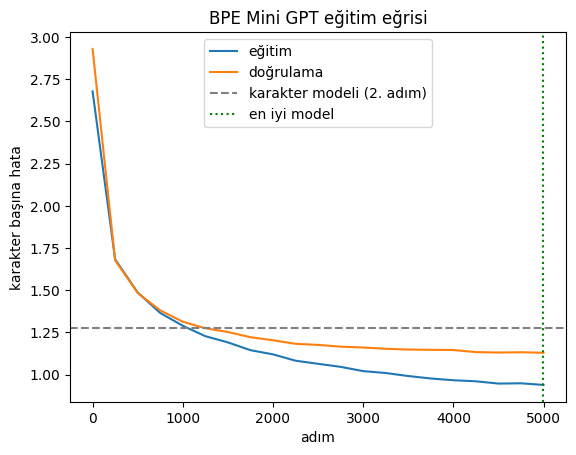

In [14]:
import matplotlib.pyplot as plt
adimlar = [g[0] for g in gecmis]
plt.plot(adimlar, [g[1] for g in gecmis], label="eğitim")
plt.plot(adimlar, [g[2] for g in gecmis], label="doğrulama")
plt.axhline(1.275, color="gray", linestyle="--", label="karakter modeli (2. adım)")
plt.axvline(en_iyi["adim"], color="green", linestyle=":", label="en iyi model")
plt.xlabel("adım"); plt.ylabel("karakter başına hata"); plt.legend()
plt.title("BPE Mini GPT eğitim eğrisi")
plt.show()

## 9. Metin üretimi (en iyi modelle)
Artık model kelime parçalarıyla yazıyor; 120 token yaklaşık 350–400 karaktere denk gelir.

In [15]:
for baslangic in ["Türkiye", "İstanbul", "Osmanlı İmparatorluğu"]:
    print(f"=== '{baslangic}' ===")
    print(uret(model, baslangic, 120, sicaklik=0.8, top_k=40))
    print()

=== 'Türkiye' ===
Türkiye'nin başkanı seçildi. Cumhurbaşkanlığı seçilemedi ve seçilmesinden sonra ikinci seçildi.

Demokrasi 
Türkiye'nin ilk başbakanlık dönemine kadar başlayan parti genel başkanlığında seçildi. Cumhurbaşkanı seçilmeyi üzerine çoğunluk sistemi seçildi ve bu nedenle, cumhurbaşkanlığı görevine başlamasına sürüldü.

Bilim ve Kalkınma Partisi, Başkanlığı görevine de yargılanacakları için genel başkanlardan kaldırılan, cumhurbaşkanlığı seçim

=== 'İstanbul' ===
İstanbul ilinde yine Sivas ilinde sivil sivil ilçe, köyleri, ilçelerinde, köylerindeki köylerde yer alan Valisi, merkez ilçelerde bulunmaktadır.

Van'ın merkezindeki Mevin'in doğu sınırında Sivas ili, merkezi olarak yer alır.

İl genel birimleri: Van iline bağlar.

Çoğunlu il, ilçe sınırları içinde kalan ilçe sınırları içerisindedir.

Coğrafya bakımından geçer. İl

=== 'Osmanlı İmparatorluğu' ===
Osmanlı İmparatorluğu'nda da, Osmanlı İmparatorluğu'nun içine katıldığı ve 18. yüzyılın sonlarında Kafkasya Devleti'ne ka

## 10. Alıştırmalar
1. **Sözlük boyutu:** `SOZLUK_HEDEF = 512` ve `8192` ile dene. Sıkıştırma oranı ve karakter başına hata nasıl değişiyor? (Her deneyde `TOKENIZER_DOSYASI` ve `CKPT_EN_IYI` adlarını değiştir.)
2. **Dropout:** Aşırı öğrenme erken başlıyorsa `dropout=0.2` dene. Erken durdurma adımı ileri kayıyor mu?
3. **Tokenları incele:** `sorted(tok.sozluk.values(), key=len)[-30:]` ile en uzun tokenlara bak. Hangi kelimeler tek token olmuş?
4. **Kendi cümlen:** `goster("...")` ile okulunla ilgili bir cümleyi tokenlara ayır. Hangi kelimeler parçalanıyor, neden?

## Sonuç tablosu
| Model | Tokenizer | Sözlük | Parametre | Karakter başına doğrulama hatası | En iyi adım |
|---|---|---|---|---|---|
| 2. adım | Karakter | 120 | 3,25 M | 1,275 | 4999 |
| 3. adım | BPE | 2048 |  |  |  |